# 01 - Eksplorasi Data (EDA)

**Tahap 2.** Mengenal dataset `disaster_clean.csv` sebelum membangun mesin pencari: ukuran, sebaran jenis bencana, panjang dokumen, dan kosakata.

In [1]:
# Pindah ke root proyek agar `import src...` dan path data berfungsi
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

## 1. Gambaran umum

In [2]:
from src.config import DATA_CSV, TEXT_COLUMN
df = pd.read_csv(DATA_CSV)
print("Bentuk data:", df.shape)
df[["doc_id", "event", "disaster_type", "year", TEXT_COLUMN]].head(8)

Bentuk data: (500, 8)


,doc_id,event,disaster_type,year,text_clean
0,1,hurricane-pablo-2012,hurricane,2012,typhoon bopha paplo killed people in philipines.
1,2,wildfire-california-2014,wildfire,2014,"wildfires leave california vulnerable to flooding, mudslides"
2,3,transportation-glasgow-helicopter-crash-2013,transportation,2013,ninth clutha funeral to be held: the funeral of a man who died in the clutha helicopte...
3,4,flood-alberta-2013,flood,2013,bc gov't offers to help alberta during flood crisis.
4,5,wildfire-california-2014,wildfire,2014,california wildfires devastating effect on marijuana industry -
5,6,earthquake-nepal-2018,earthquake,2018,nepalearthquake | school children injured in westbengal live updates -
6,7,flood-philipinnes-2012,flood,2012,i'm kinda sad & worried about manila's current flood. it's gotten worse in some areas.
7,8,wildfire-colorado-2012,wildfire,2012,"as awful as the flagstafffire is, the waldofire is a different ballgame. that's some a..."


In [3]:
print("Nilai kosong per kolom:")
print(df.isna().sum().to_string())
print("\nJumlah event unik:", df["event"].nunique())
print("Jumlah teks duplikat:", df[TEXT_COLUMN].duplicated().sum())

Nilai kosong per kolom:
doc_id           0
tweet_id         0
event            0
disaster_type    0
year             0
text_raw         0
relevance        0
text_clean       0

Jumlah event unik: 47
Jumlah teks duplikat: 0


## 2. Sebaran jenis bencana dan tahun

Koleksi diambil dengan sampling berstrata per event, sehingga jumlah dokumen per event relatif seimbang. Jenis bencana yang punya banyak event (earthquake, flood, hurricane) otomatis lebih banyak dokumennya.

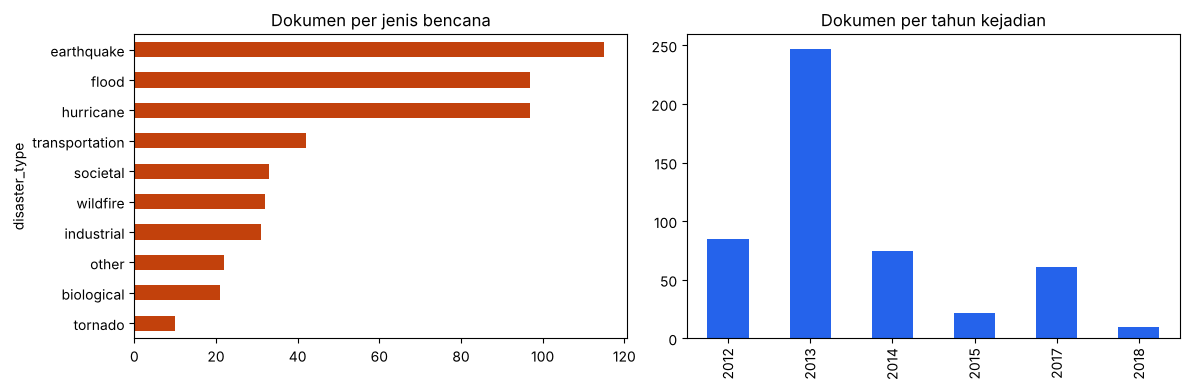

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["disaster_type"].value_counts().sort_values().plot.barh(ax=ax[0], color="#c2410c")
ax[0].set_title("Dokumen per jenis bencana")
df["year"].value_counts().sort_index().plot.bar(ax=ax[1], color="#2563eb")
ax[1].set_title("Dokumen per tahun kejadian"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

In [5]:
df.groupby("disaster_type")["event"].nunique().sort_values(ascending=False).rename("jumlah_event").to_frame()

,jumlah_event
disaster_type,
earthquake,11
flood,9
hurricane,9
transportation,4
wildfire,3
industrial,3
societal,3
biological,2
other,2


## 3. Panjang dokumen

Tweet sangat pendek. Ini penting untuk STKI: dengan sedikit kata per dokumen, skor cosine cenderung kecil dan banyak dokumen hanya cocok pada satu dua term.

count    500.0
mean      13.7
std        4.9
min        5.0
25%       10.0
50%       13.5
75%       17.0
max       27.0


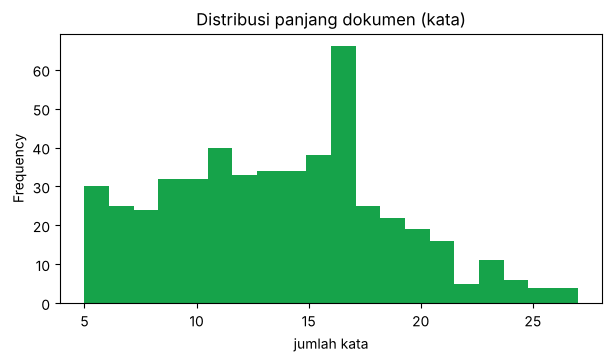

In [6]:
df["n_kata"] = df[TEXT_COLUMN].str.split().str.len()
print(df["n_kata"].describe().round(1).to_string())
df["n_kata"].plot.hist(bins=20, color="#16a34a", figsize=(7, 3.5), title="Distribusi panjang dokumen (kata)")
plt.xlabel("jumlah kata"); plt.show()

## 4. Kosakata setelah preprocessing

Teks diproses dengan pipeline yang sama dengan mesin pencari (cleaning, case folding, tokenizing, stopword removal, stemming).

Total token         : 4408
Ukuran vocabulary   : 1855
Term muncul 1x saja : 1176


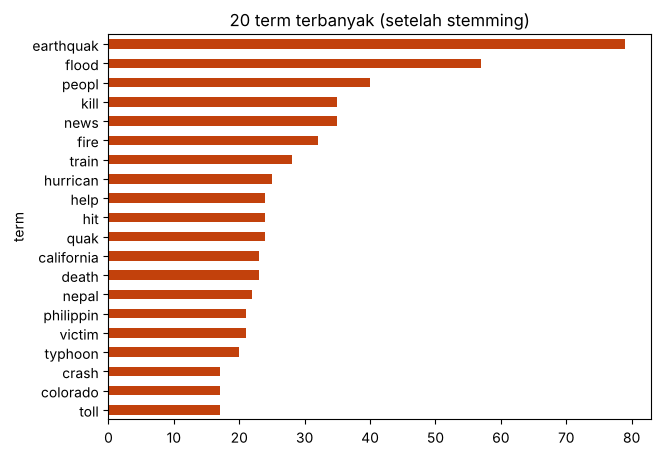

In [7]:
from collections import Counter
from src.preprocessing import preprocess

tokens_per_doc = [preprocess(t) for t in df[TEXT_COLUMN]]
all_tokens = [t for toks in tokens_per_doc for t in toks]
freq = Counter(all_tokens)
print("Total token         :", len(all_tokens))
print("Ukuran vocabulary   :", len(freq))
print("Term muncul 1x saja :", sum(1 for c in freq.values() if c == 1))
top = pd.DataFrame(freq.most_common(20), columns=["term", "frekuensi"])
top.set_index("term").plot.barh(figsize=(7, 5), legend=False, color="#c2410c").invert_yaxis()
plt.title("20 term terbanyak (setelah stemming)"); plt.show()

Sebagian besar term hanya muncul sekali (ciri khas teks: sedikit term sangat sering, banyak term sangat jarang). Term yang jarang justru bernilai tinggi pada IDF.

In [8]:
# Term khas per jenis bencana
for jenis in ["earthquake", "flood", "wildfire", "transportation"]:
    c = Counter(t for toks, d in zip(tokens_per_doc, df["disaster_type"]) if d == jenis for t in toks)
    print(f"{jenis:15s}", [w for w, _ in c.most_common(8)])

earthquake      ['earthquak', 'quak', 'magnitud', 'nepal', 'guatemala', 'hit', 'costa', 'rica']
flood           ['flood', 'mora', 'india', 'peopl', 'sardinia', 'colorado', 'reliefph', 'help']
wildfire        ['fire', 'wildfir', 'california', 'colorado', 'nswfire', 'home', 'sydney', 'spring']
transportation  ['train', 'crash', 'derail', 'spain', 'clutha', 'helicopt', 'driver', 'kill']


## Kesimpulan

- Dokumen sangat pendek, sehingga perlu pembobotan yang tidak bergantung pada panjang dokumen (normalisasi L2 pada vektor TF-IDF).
- Kosakata kecil dan banyak term jarang, sehingga IDF berperan membedakan term khas (mis. nama tempat) dari term umum.
- Tidak ada nilai kosong pada kolom utama; duplikat sudah disaring pada tahap 1.